Dataset: (4000, 1280) (array(['ASK', 'FSK', 'PSK', 'QAM'], dtype='<U3'), array([1000, 1000, 1000, 1000]))


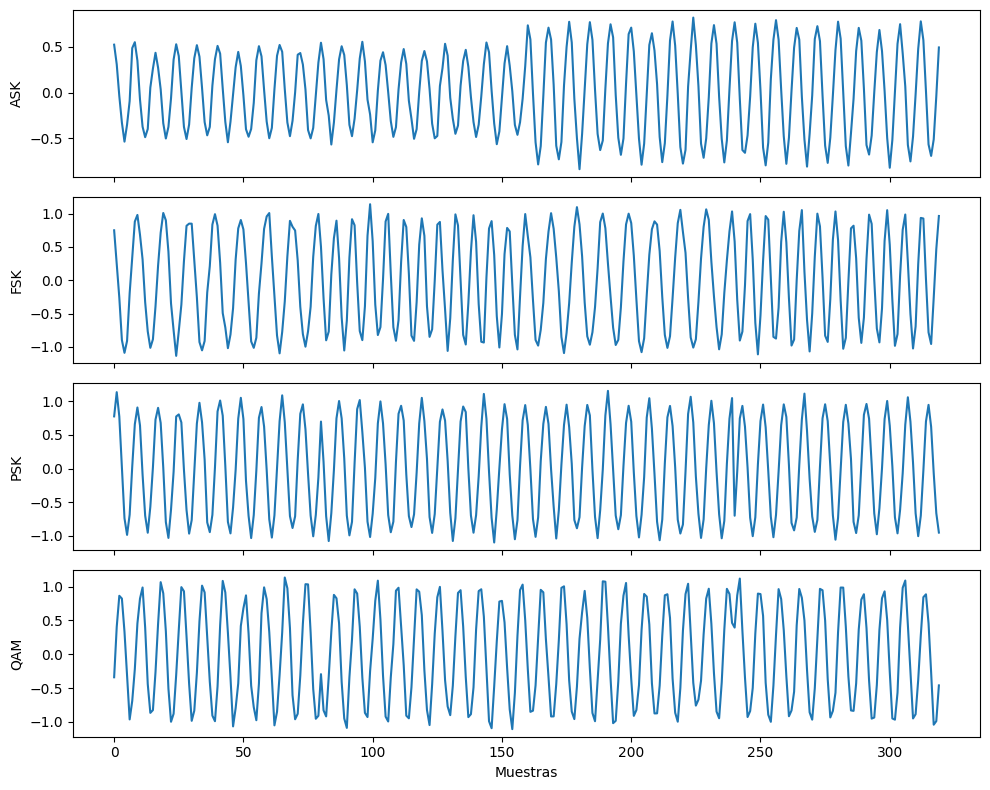

Entrenamiento: (3200, 1280) Prueba: (800, 1280)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)

fs = 80_000
fc = 10_000
Rs = 1_000
sps = fs // Rs
N_SIM = 16
SNR_LIST = [0, 5, 10, 15, 20]
MUESTRAS_POR_MOD = 1000


def _t():
    return np.arange(N_SIM * sps) / fs


def gen_ask(rng):
    niveles = np.array([0.25, 0.5, 0.75, 1.0])
    a = np.repeat(rng.choice(niveles, N_SIM), sps)
    return a * np.cos(2 * np.pi * fc * _t())


def gen_fsk(rng):
    delta = 2_000
    bits = np.repeat(rng.integers(0, 2, N_SIM), sps)
    f = fc + np.where(bits == 1, delta, -delta)
    fase = 2 * np.pi * np.cumsum(f) / fs
    return np.cos(fase)


def gen_psk(rng):
    fases = rng.choice([np.pi/4, 3*np.pi/4, 5*np.pi/4, 7*np.pi/4], N_SIM)
    return np.cos(2 * np.pi * fc * _t() + np.repeat(fases, sps))


def gen_qam16(rng):
    niveles = np.array([-3, -1, 1, 3]) / np.sqrt(10)
    I = np.repeat(rng.choice(niveles, N_SIM), sps)
    Q = np.repeat(rng.choice(niveles, N_SIM), sps)
    t = _t()
    return I * np.cos(2 * np.pi * fc * t) - Q * np.sin(2 * np.pi * fc * t)


GENERADORES = {"ASK": gen_ask, "FSK": gen_fsk, "PSK": gen_psk, "QAM": gen_qam16}


def agregar_awgn(senal, snr_db, rng):
    p_senal = np.mean(senal ** 2)
    p_ruido = p_senal / (10 ** (snr_db / 10))
    ruido = rng.normal(0, np.sqrt(p_ruido), senal.shape)
    return senal + ruido


def generar_dataset(rng):
    X, y, snrs = [], [], []
    for nombre, gen in GENERADORES.items():
        for i in range(MUESTRAS_POR_MOD):
            snr = SNR_LIST[i % len(SNR_LIST)]
            s = agregar_awgn(gen(rng), snr, rng)
            s = s / np.max(np.abs(s))
            X.append(s.astype(np.float32))
            y.append(nombre)
            snrs.append(snr)
    return np.array(X), np.array(y), np.array(snrs)


X, y, snr = generar_dataset(rng)
print("Dataset:", X.shape, np.unique(y, return_counts=True))

fig, axs = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for ax, (nombre, gen) in zip(axs, GENERADORES.items()):
    ax.plot(agregar_awgn(gen(rng), 20, rng)[: 4 * sps])
    ax.set_ylabel(nombre)
axs[-1].set_xlabel("Muestras")
plt.tight_layout()
plt.show()

X_train, X_test, y_train, y_test, snr_train, snr_test = train_test_split(
    X, y, snr, test_size=0.20, stratify=y, random_state=42
)
print("Entrenamiento:", X_train.shape, "Prueba:", X_test.shape)

np.savez_compressed(
    "dataset_modulaciones.npz",
    X_train=X_train, y_train=y_train, snr_train=snr_train,
    X_test=X_test, y_test=y_test, snr_test=snr_test,
)